In [ ]:
!pip install -q influxdb-client

In [ ]:
import sys, json, itertools, warnings, time
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

EN_COLAB = "google.colab" in sys.modules

# ---- Fuente de datos: "influx" (real), "csv" (archivo subido) o "demo" (sintética)
FUENTE = "influx"

MEASUREMENT = "Server"              # <-- escribe tu measurement
FIELD = "Consumo_total"                    # <-- escribe tu field
TAG_KEY, TAG_VALUE = "", ""   # p.ej. "device", "esp32_01" (vacío = sin filtro)

DIAS_ENTRENAMIENTO = 30       # historia a descargar
HORAS_TEST = 24               # últimas horas reservadas para evaluar
S = 24                        # periodo estacional: 24 h (ciclo diario)

def secreto(nombre, defecto=""):
    if EN_COLAB:
        from google.colab import userdata
        try:
            return userdata.get(nombre)
        except Exception:
            return defecto
    import os
    return os.getenv(nombre, defecto)

INFLUX_URL, INFLUX_TOKEN = secreto("INFLUX_URL"), secreto("INFLUX_TOKEN")
INFLUX_ORG, INFLUX_BUCKET = secreto("INFLUX_ORG"), secreto("INFLUX_BUCKET")
print("Fuente:", FUENTE, "| InfluxDB:", INFLUX_URL or "(sin configurar)", "| bucket:", INFLUX_BUCKET or "-")


Fuente: influx | InfluxDB: https://us-east-1-1.aws.cloud2.influxdata.com/ | bucket: Consumo_elec


In [ ]:
def construir_flux(horas):
    filtro_tag = f'\n  |> filter(fn: (r) => r["{TAG_KEY}"] == "{TAG_VALUE}")' if TAG_KEY and TAG_VALUE else ""
    return f"""
from(bucket: "{INFLUX_BUCKET}")
  |> range(start: -{horas + 2}h)
  |> filter(fn: (r) => r["_measurement"] == "{MEASUREMENT}")
  |> filter(fn: (r) => r["_field"] == "{FIELD}"){filtro_tag}
  |> aggregateWindow(every: 1h, fn: mean, createEmpty: false, timeSrc: "_start")
  |> keep(columns: ["_time", "_value"])
  |> sort(columns: ["_time"])
"""

def preparar_serie_horaria(tiempos, valores, horas):
    if len(tiempos) == 0:
        return pd.Series(dtype=float, name="valor")
    idx = pd.to_datetime(pd.Series(tiempos), utc=True).dt.tz_localize(None).dt.floor("h")
    s = pd.Series(np.asarray(valores, dtype=float), index=pd.DatetimeIndex(idx), name="valor")
    s = s.groupby(level=0).mean().sort_index()
    hora_actual = pd.Timestamp.now(tz="UTC").tz_localize(None).floor("h")
    s = s[s.index < hora_actual]                       # quita la hora incompleta
    if s.empty:
        return s
    rango = pd.date_range(s.index.min(), s.index.max(), freq="h")
    s = s.reindex(rango)
    huecos = s.isna()                                  # horas sin dato antes de rellenar
    s = s.interpolate(method="time", limit=6).ffill().bfill()
    s.index.name = "tiempo"
    s = s.iloc[-horas:].asfreq("h")
    s.attrs["horas_rellenadas"] = int(huecos.reindex(s.index).sum())
    return s

def leer_influx(horas):
    from influxdb_client import InfluxDBClient
    with InfluxDBClient(url=INFLUX_URL, token=INFLUX_TOKEN, org=INFLUX_ORG, timeout=60_000) as c:
        tablas = c.query_api().query(construir_flux(horas), org=INFLUX_ORG)
    t, v = [], []
    for tabla in tablas:
        for r in tabla.records:
            if r.get_value() is not None:
                t.append(r.get_time()); v.append(r.get_value())
    return preparar_serie_horaria(t, v, horas)

def serie_demo(horas, semilla=7):
    fin = pd.Timestamp.now(tz="UTC").tz_localize(None).floor("h") - pd.Timedelta(hours=1)
    idx = pd.date_range(end=fin, periods=horas, freq="h")
    hora_local = (idx.hour - 5) % 24
    rng = np.random.default_rng(semilla)
    v = 22 + 5*np.sin(2*np.pi*(hora_local-9)/24) + rng.normal(0, 0.6, horas)
    return pd.Series(v, index=idx, name="valor").asfreq("h")

horas = DIAS_ENTRENAMIENTO * 24
if FUENTE == "influx":
    assert MEASUREMENT and FIELD, "Escribe MEASUREMENT y FIELD en la celda 0. Configuración."
    serie = leer_influx(horas)
elif FUENTE == "csv":
    # CSV con columnas "tiempo" (UTC) y "valor"
    from google.colab import files
    nombre = next(iter(files.upload()))
    df = pd.read_csv(nombre)
    serie = preparar_serie_horaria(df["tiempo"], df["valor"], horas)
else:
    serie = serie_demo(horas)

print(f"{len(serie)} horas  |  {serie.index.min()} → {serie.index.max()} (UTC)  |  "
      f"horas rellenadas: {serie.attrs.get('horas_rellenadas', 0)}")
assert len(serie) >= 7 * S, "Se recomiendan al menos 7 días de datos para un SARIMA con s=24."
serie.describe()


720 horas  |  2026-10-05 21:00:00 → 2026-11-04 20:00:00 (UTC)  |  horas rellenadas: 0


,valor
count,720.000000
mean,269.131382
std,86.925197
min,107.590287
25%,194.011709
50%,246.863972
75%,329.291542
max,619.591957


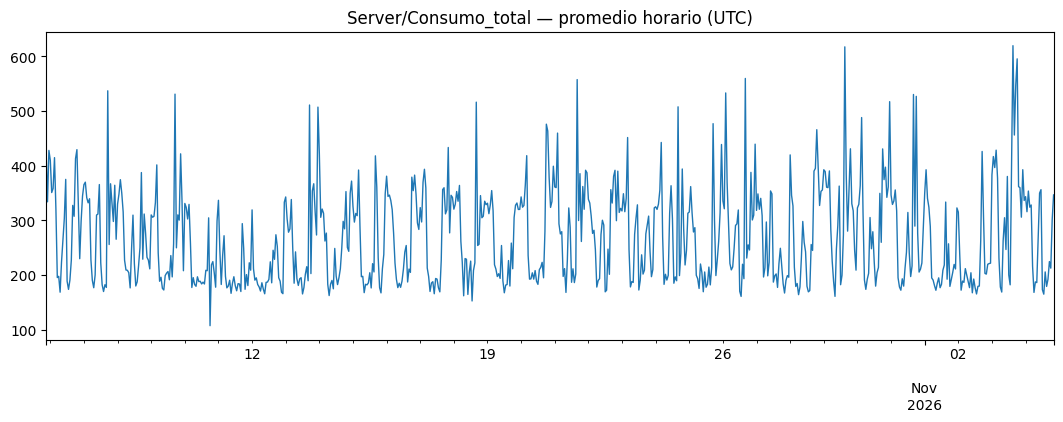

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))
serie.plot(ax=ax, lw=1)
ax.set_title(f"{MEASUREMENT}/{FIELD} — promedio horario (UTC)"); ax.set_xlabel("")
plt.show()

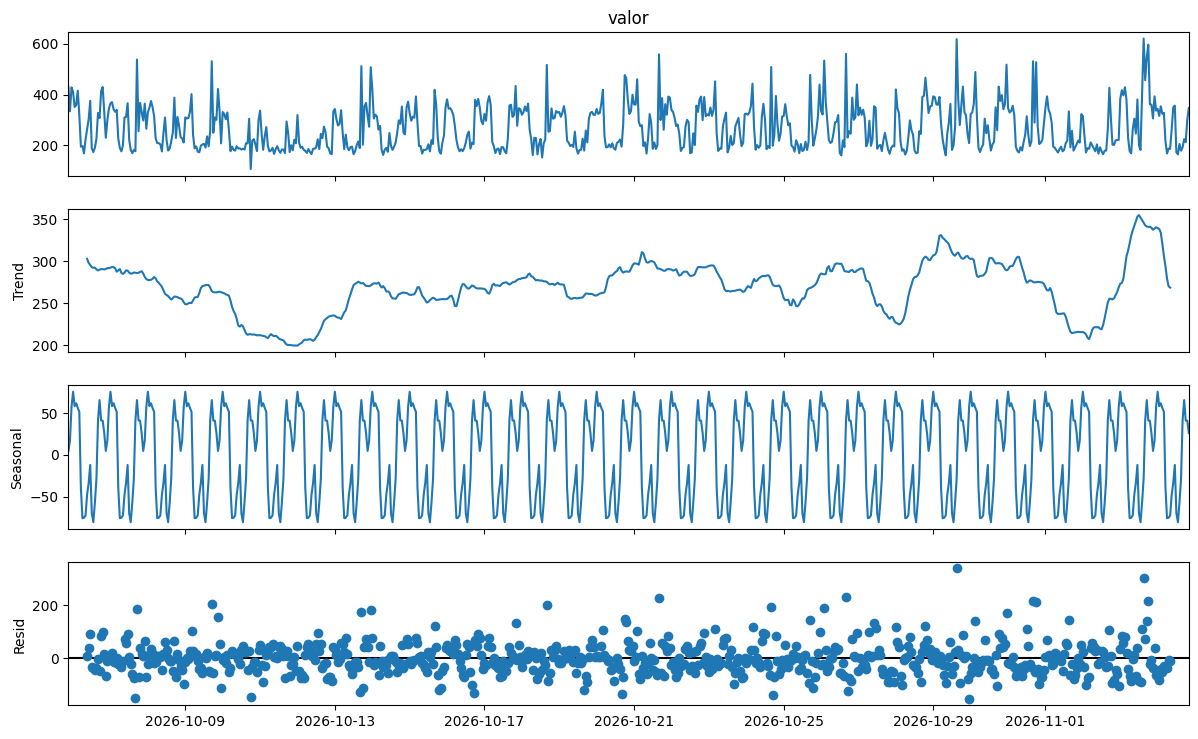

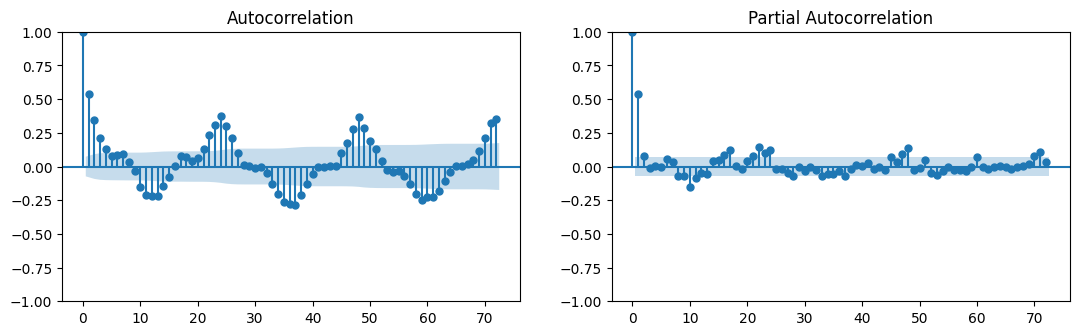

In [ ]:
seasonal_decompose(serie, period=S).plot().set_size_inches(13, 8); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(serie, lags=72, ax=axs[0]); plot_pacf(serie, lags=72, ax=axs[1], method="ywm")
plt.show()

In [ ]:
K = 3
q1, q3 = serie.quantile([0.25, 0.75])
lim_sup, lim_inf = q3 + K * (q3 - q1), q1 - K * (q3 - q1)
atipicos = serie[(serie > lim_sup) | (serie < lim_inf)]
print(f"Límites: [{lim_inf:.1f}, {lim_sup:.1f}]  |  atípicos encontrados: {len(atipicos)}")
print(atipicos)

serie = serie.mask((serie > lim_sup) | (serie < lim_inf)).interpolate(method="time")
print("Nuevo rango:", round(serie.min(), 1), "a", round(serie.max(), 1))

Límites: [-211.8, 735.1]  |  atípicos encontrados: 0
Series([], Freq: h, Name: valor, dtype: float64)
Nuevo rango: 107.6 a 619.6


In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    p_valor = adfuller(serie.dropna())[1]
d = 0 if p_valor < 0.05 else 1
print(f"ADF p-valor = {p_valor:.4f}  →  d = {d}")

entrenamiento, prueba = serie.iloc[:-HORAS_TEST], serie.iloc[-HORAS_TEST:]
print(f"Entrenamiento: {len(entrenamiento)} h | Prueba: {len(prueba)} h")


ADF p-valor = 0.0000  →  d = 0
Entrenamiento: 696 h | Prueba: 24 h


In [ ]:
D = 1
rejilla = list(itertools.product(range(3), range(3), range(2), range(2)))  # p, q, P, Q
resultados = []
t0 = time.time()
for i, (p, q, P, Q) in enumerate(rejilla, 1):
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            r = SARIMAX(entrenamiento, order=(p, d, q), seasonal_order=(P, D, Q, S),
                        enforce_stationarity=False, enforce_invertibility=False
                        ).fit(disp=False, maxiter=50)
        resultados.append({"order": (p, d, q), "seasonal_order": (P, D, Q, S), "aic": r.aic})
    except Exception as e:
        print("falló", (p, d, q), (P, D, Q, S), e)
    print(f"\r{i}/{len(rejilla)} modelos  ({time.time()-t0:.0f} s)", end="")

tabla = pd.DataFrame(resultados).sort_values("aic").reset_index(drop=True)
mejor = tabla.iloc[0]
print(f"\n\nMejor: SARIMA{mejor.order}x{mejor.seasonal_order}  AIC={mejor.aic:.1f}")
tabla.head(8)

36/36 modelos  (117 s)

Mejor: SARIMA(1, 0, 2)x(0, 1, 1, 24)  AIC=7248.4


,order,seasonal_order,aic
0,"(1, 0, 2)","(0, 1, 1, 24)",7248.373753
1,"(1, 0, 2)","(1, 1, 1, 24)",7248.544319
2,"(2, 0, 2)","(1, 1, 1, 24)",7249.380414
3,"(2, 0, 2)","(0, 1, 1, 24)",7249.454630
4,"(2, 0, 1)","(0, 1, 1, 24)",7260.012694
5,"(2, 0, 1)","(1, 1, 1, 24)",7260.338998
6,"(1, 0, 1)","(1, 1, 1, 24)",7269.749991
7,"(1, 0, 1)","(0, 1, 1, 24)",7269.980840


,SARIMA,Ingenua estacional
MAE,71.475,113.329
RMSE,83.325,165.033
MAPE_%,30.871,48.941


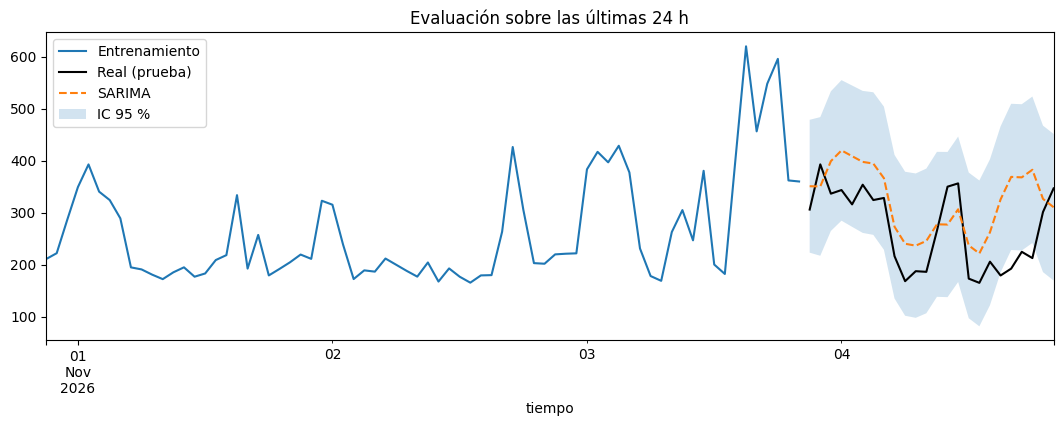

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_eval = SARIMAX(entrenamiento, order=mejor.order, seasonal_order=mejor.seasonal_order,
                          enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
pron = modelo_eval.get_forecast(HORAS_TEST).summary_frame(alpha=0.05)
ingenua = entrenamiento.iloc[-S:].values[:HORAS_TEST] if HORAS_TEST <= S else np.resize(entrenamiento.iloc[-S:].values, HORAS_TEST)

def metricas(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    mape = np.mean(np.abs((real - pred) / np.where(real == 0, np.nan, real))) * 100
    return {"MAE": float(np.mean(np.abs(real - pred))),
            "RMSE": float(np.sqrt(np.mean((real - pred) ** 2))),
            "MAPE_%": float(np.nanmean(mape)) if np.isfinite(mape) else None}

m_sarima, m_ingenua = metricas(prueba, pron["mean"]), metricas(prueba, ingenua)
display(pd.DataFrame({"SARIMA": m_sarima, "Ingenua estacional": m_ingenua}).round(3))

fig, ax = plt.subplots(figsize=(13, 4))
entrenamiento.iloc[-72:].plot(ax=ax, label="Entrenamiento")
prueba.plot(ax=ax, label="Real (prueba)", color="k")
pron["mean"].plot(ax=ax, label="SARIMA", ls="--")
ax.fill_between(pron.index, pron["mean_ci_lower"], pron["mean_ci_upper"], alpha=.2, label="IC 95 %")
ax.legend(); ax.set_title("Evaluación sobre las últimas 24 h"); plt.show()


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9173      0.043     21.138      0.000       0.832       1.002
ma.L1         -1.0650      0.129     -8.263      0.000      -1.318      -0.812
ma.L2         -0.2363      0.043     -5.478      0.000      -0.321      -0.152
ma.S.L24      -1.1169      0.021    -54.003      0.000      -1.157      -1.076
sigma2      2141.6947    367.432      5.829      0.000    1421.542    2861.847


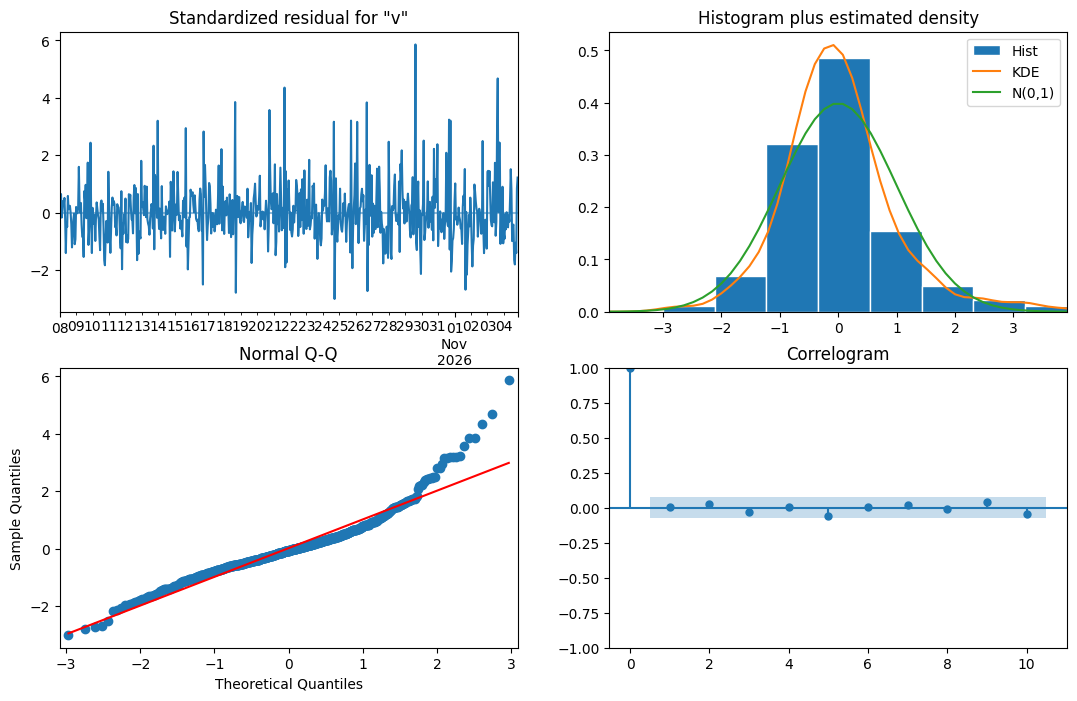

,lb_stat,lb_pvalue
24,16.734975,0.859743
48,33.811651,0.939665


In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    modelo_final = SARIMAX(serie, order=mejor.order, seasonal_order=mejor.seasonal_order,
                           enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
print(modelo_final.summary().tables[1])
modelo_final.plot_diagnostics(figsize=(13, 8)); plt.show()

# Prueba de Ljung-Box: p-valor > 0.05 = no queda autocorrelación (ni diaria) en los residuos.
# Se descartan los primeros residuos (arranque del filtro: con D=1 y s=24 los primeros
# ~24 valores no tienen con qué compararse y son enormes; plot_diagnostics también los omite).
from statsmodels.stats.diagnostic import acorr_ljungbox
residuos = modelo_final.resid[modelo_final.loglikelihood_burn:]
acorr_ljungbox(residuos, lags=[24, 48])

In [ ]:
config = {
    "tipo": "SARIMAX (statsmodels)",
    "order": [int(x) for x in mejor.order],
    "seasonal_order": [int(x) for x in mejor.seasonal_order],
    "trend": None,
    "enforce_stationarity": False,
    "enforce_invertibility": False,
    "freq": "h",
    "params": {k: float(v) for k, v in modelo_final.params.items()},
    "measurement": MEASUREMENT,
    "field": FIELD,
    "tag": {TAG_KEY: TAG_VALUE} if TAG_KEY else None,
    "n_observaciones": int(len(serie)),
    "rango_entrenamiento": {"inicio": str(serie.index[0]), "fin": str(serie.index[-1])},
    "metricas_test": {k: round(v, 4) for k, v in m_sarima.items() if v is not None},
    "metricas_ingenua": {k: round(v, 4) for k, v in m_ingenua.items() if v is not None},
    "aic": float(modelo_final.aic),
    "entrenado_en": datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC"),
    "versiones": {"statsmodels": statsmodels.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
with open("sarima_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2, ensure_ascii=False)
print(json.dumps({k: config[k] for k in ["order", "seasonal_order", "params", "metricas_test"]}, indent=2))


{
  "order": [
    1,
    0,
    2
  ],
  "seasonal_order": [
    0,
    1,
    1,
    24
  ],
  "params": {
    "ar.L1": 0.91731317072149,
    "ma.L1": -1.065035336976422,
    "ma.L2": -0.2362760487531943,
    "ma.S.L24": -1.1168636622101846,
    "sigma2": 2141.6947248716183
  },
  "metricas_test": {
    "MAE": 71.4745,
    "RMSE": 83.3246,
    "MAPE_%": 30.8713
  }
}


In [ ]:

with open("sarima_config.json") as f:
    cfg = json.load(f)
m = SARIMAX(serie, order=tuple(cfg["order"]), seasonal_order=tuple(cfg["seasonal_order"]),
            trend=cfg["trend"], enforce_stationarity=cfg["enforce_stationarity"],
            enforce_invertibility=cfg["enforce_invertibility"])
r = m.filter(np.array([cfg["params"][n] for n in m.param_names]))     # sin reentrenar
api = r.get_forecast(12).predicted_mean
original = modelo_final.get_forecast(12).predicted_mean
print("Diferencia máxima API vs. modelo original:", float(np.max(np.abs(api - original))))
api.round(3).to_frame("pronóstico próximas 12 h (UTC)")

Diferencia máxima API vs. modelo original: 0.0


,pronóstico próximas 12 h (UTC)
2026-11-04 21:00:00,265.566
2026-11-04 22:00:00,268.419
2026-11-04 23:00:00,310.526
2026-11-05 00:00:00,332.397
2026-11-05 01:00:00,323.059
2026-11-05 02:00:00,324.267
2026-11-05 03:00:00,321.222
2026-11-05 04:00:00,303.792
2026-11-05 05:00:00,212.076
2026-11-05 06:00:00,180.296


In [ ]:
if EN_COLAB:
    from google.colab import files
    files.download("sarima_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>